In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/competitions/demand-forecasting-kernels-only/sample_submission.csv
/kaggle/input/competitions/demand-forecasting-kernels-only/train.csv
/kaggle/input/competitions/demand-forecasting-kernels-only/test.csv


In [4]:


train_path = '/kaggle/input/competitions/demand-forecasting-kernels-only/train.csv'

df = pd.read_csv(train_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [5]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB

Statistical Summary:


,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000



Column Names:
['date', 'store', 'item', 'sales']


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Stores:", df['store'].nunique())
print("Unique Products:", df['item'].nunique())

print("\nDate Range:")
print("Start:", df['date'].min())
print("End:", df['date'].max())

Missing Values:
date     0
store    0
item     0
sales    0
dtype: int64

Duplicate Rows: 0

Unique Stores: 10
Unique Products: 50

Date Range:
Start: 2013-01-01
End: 2017-12-31


In [7]:

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

display(df.head())

print("Date conversion completed!")
print("Date column type:", df['date'].dtype)

,date,store,item,sales,year,month,day,day_of_week
0,2013-01-01,1,1,13,2013,1,1,1
1,2013-01-02,1,1,11,2013,1,2,2
2,2013-01-03,1,1,14,2013,1,3,3
3,2013-01-04,1,1,13,2013,1,4,4
4,2013-01-05,1,1,10,2013,1,5,5


Date conversion completed!
Date column type: datetime64[ns]


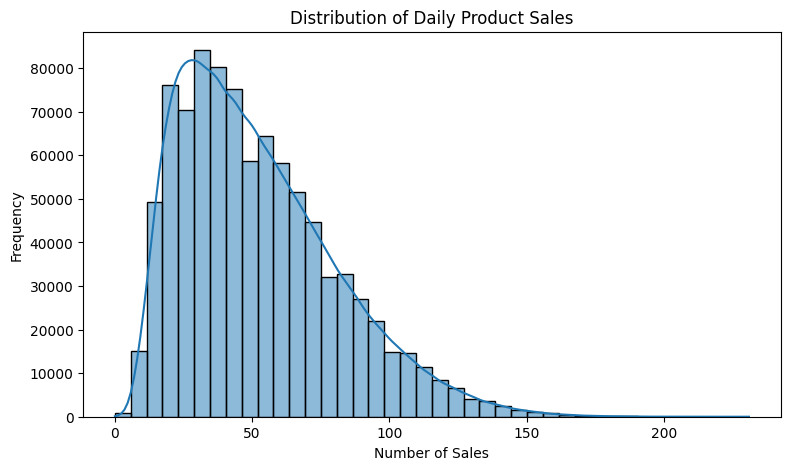

In [8]:
plt.figure(figsize=(9,5))

sns.histplot(df['sales'], bins=40, kde=True)

plt.title('Distribution of Daily Product Sales')
plt.xlabel('Number of Sales')
plt.ylabel('Frequency')

plt.show()

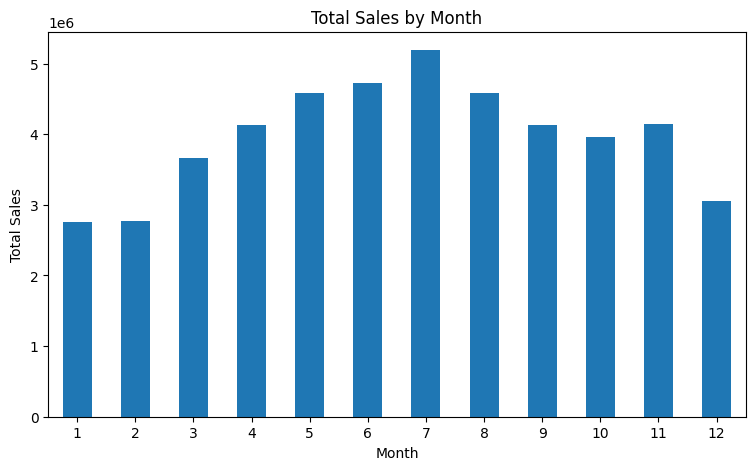

In [9]:
monthly_sales = df.groupby('month')['sales'].sum()

plt.figure(figsize=(9,5))

monthly_sales.plot(kind='bar')

plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

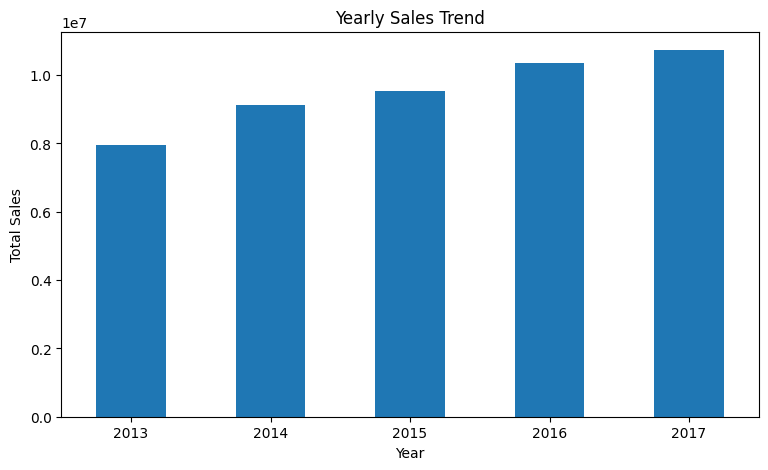

In [10]:
yearly_sales = df.groupby('year')['sales'].sum()

plt.figure(figsize=(9,5))

yearly_sales.plot(kind='bar')

plt.title('Yearly Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

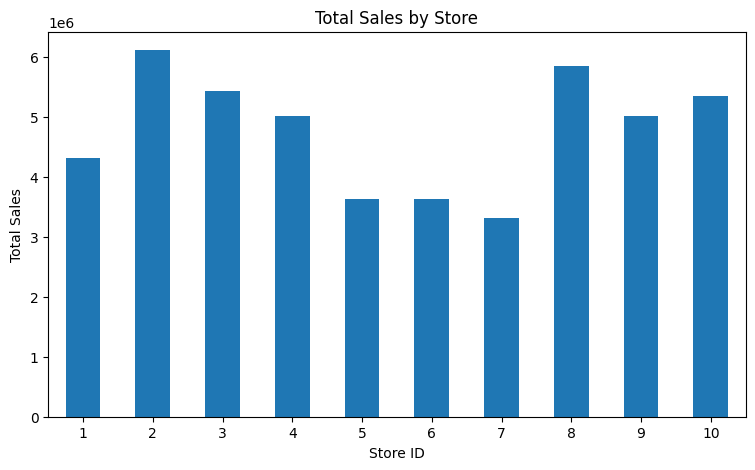

In [11]:
store_sales = df.groupby('store')['sales'].sum()

plt.figure(figsize=(9,5))

store_sales.plot(kind='bar')

plt.title('Total Sales by Store')
plt.xlabel('Store ID')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

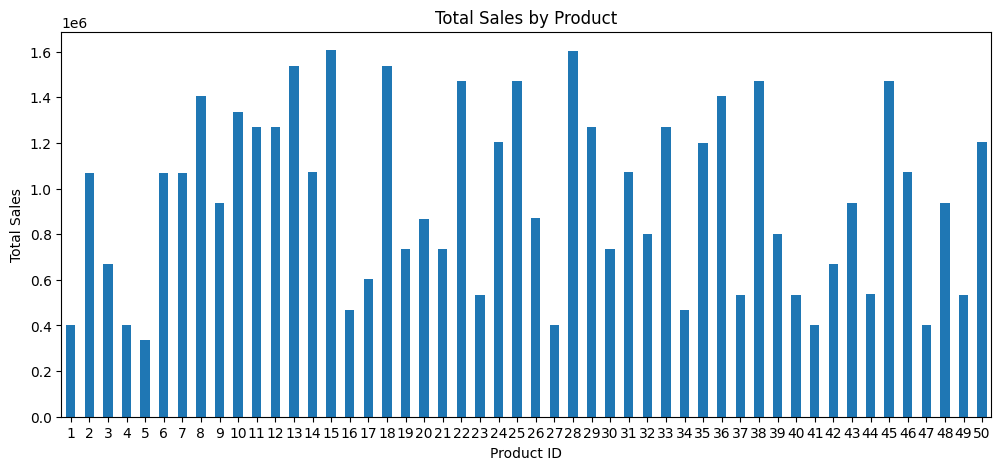

Highest Selling Product: 15
Lowest Selling Product: 5


In [12]:
item_sales = df.groupby('item')['sales'].sum()

plt.figure(figsize=(12,5))

item_sales.plot(kind='bar')

plt.title('Total Sales by Product')
plt.xlabel('Product ID')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

print("Highest Selling Product:", item_sales.idxmax())
print("Lowest Selling Product:", item_sales.idxmin())

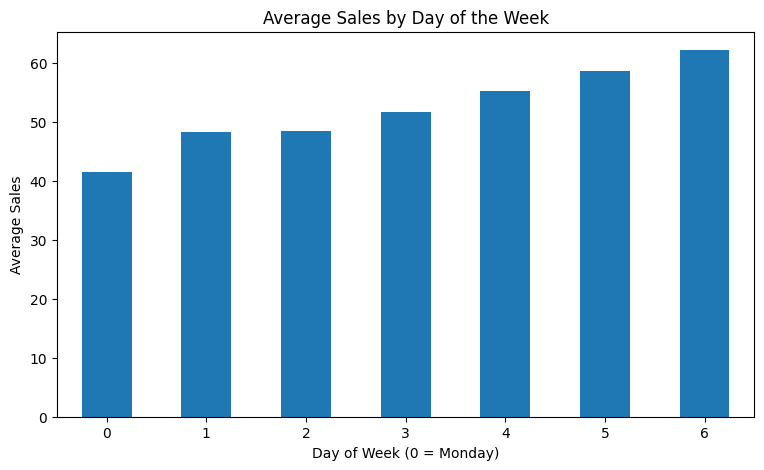

In [13]:
weekly_sales = df.groupby('day_of_week')['sales'].mean()

plt.figure(figsize=(9,5))

weekly_sales.plot(kind='bar')

plt.title('Average Sales by Day of the Week')
plt.xlabel('Day of Week (0 = Monday)')
plt.ylabel('Average Sales')

plt.xticks(rotation=0)
plt.show()

In [15]:
model_df = df.copy()


model_df = model_df.sort_values(
    ['store', 'item', 'date']
).reset_index(drop=True)


model_df['is_weekend'] = (
    model_df['day_of_week'] >= 5
).astype(int)


group = model_df.groupby(['store', 'item'])['sales']

model_df['lag_1'] = group.shift(1)
model_df['lag_7'] = group.shift(7)
model_df['lag_14'] = group.shift(14)


model_df['rolling_mean_7'] = (
    model_df.groupby(['store', 'item'])['sales']
    .transform(lambda x: x.shift(1).rolling(7).mean())
)


model_df = model_df.dropna().reset_index(drop=True)

print("Feature engineering completed!")
print("New dataset shape:", model_df.shape)

display(model_df.head())

Feature engineering completed!
New dataset shape: (906000, 13)


,date,store,item,sales,year,month,day,day_of_week,is_weekend,lag_1,lag_7,lag_14,rolling_mean_7
0,2013-01-15,1,1,5,2013,1,15,1,0,12.0,9.0,13.0,9.714286
1,2013-01-16,1,1,7,2013,1,16,2,0,5.0,12.0,11.0,9.142857
2,2013-01-17,1,1,16,2013,1,17,3,0,7.0,9.0,14.0,8.428571
3,2013-01-18,1,1,7,2013,1,18,4,0,16.0,9.0,13.0,9.428571
4,2013-01-19,1,1,18,2013,1,19,5,1,7.0,7.0,10.0,9.142857


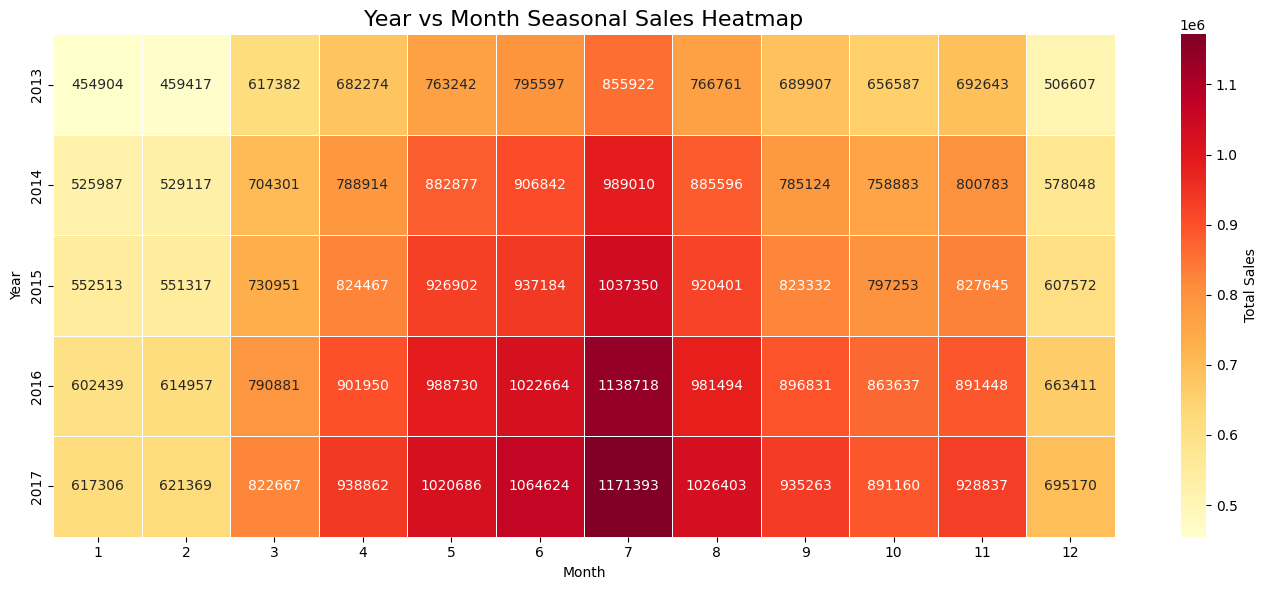

In [16]:
seasonal_sales = df.pivot_table(
    index='year',
    columns='month',
    values='sales',
    aggfunc='sum'
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    seasonal_sales,
    cmap='YlOrRd',
    annot=True,
    fmt='.0f',
    linewidths=0.5,
    cbar_kws={'label': 'Total Sales'}
)

plt.title('Year vs Month Seasonal Sales Heatmap', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Year')

plt.tight_layout()
plt.show()

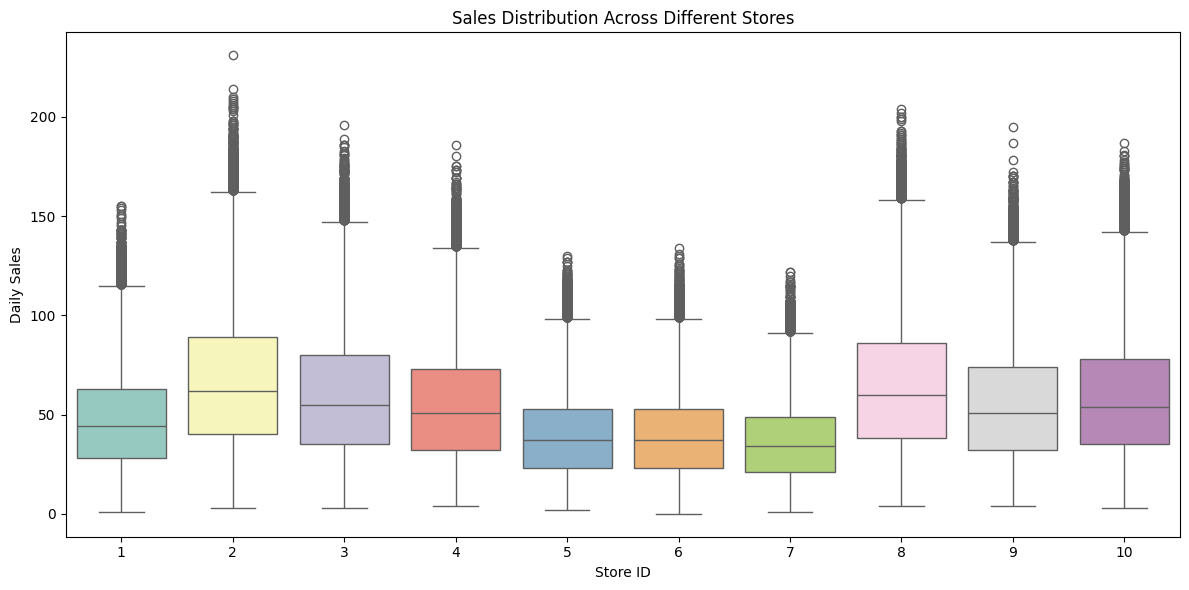

In [17]:


plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='store',
    y='sales',
    hue='store',
    palette='Set3',
    legend=False
)

plt.title('Sales Distribution Across Different Stores')
plt.xlabel('Store ID')
plt.ylabel('Daily Sales')

plt.tight_layout()
plt.show()

In [18]:

model_df = df.copy()

model_df = model_df.sort_values(
    ['store', 'item', 'date']
).reset_index(drop=True)


model_df['is_weekend'] = (
    model_df['day_of_week'] >= 5
).astype(int)

group = model_df.groupby(['store', 'item'])['sales']

model_df['lag_1'] = group.shift(1)
model_df['lag_7'] = group.shift(7)
model_df['lag_14'] = group.shift(14)



model_df['rolling_mean_7'] = (
    model_df.groupby(['store', 'item'])['sales']
    .transform(lambda x: x.shift(1).rolling(7).mean())
)


model_df = model_df.dropna().reset_index(drop=True)

print("Feature Engineering Completed!")
print("Original Dataset Shape:", df.shape)
print("New Dataset Shape:", model_df.shape)

display(model_df.head())

Feature Engineering Completed!
Original Dataset Shape: (913000, 8)
New Dataset Shape: (906000, 13)


,date,store,item,sales,year,month,day,day_of_week,is_weekend,lag_1,lag_7,lag_14,rolling_mean_7
0,2013-01-15,1,1,5,2013,1,15,1,0,12.0,9.0,13.0,9.714286
1,2013-01-16,1,1,7,2013,1,16,2,0,5.0,12.0,11.0,9.142857
2,2013-01-17,1,1,16,2013,1,17,3,0,7.0,9.0,14.0,8.428571
3,2013-01-18,1,1,7,2013,1,18,4,0,16.0,9.0,13.0,9.428571
4,2013-01-19,1,1,18,2013,1,19,5,1,7.0,7.0,10.0,9.142857


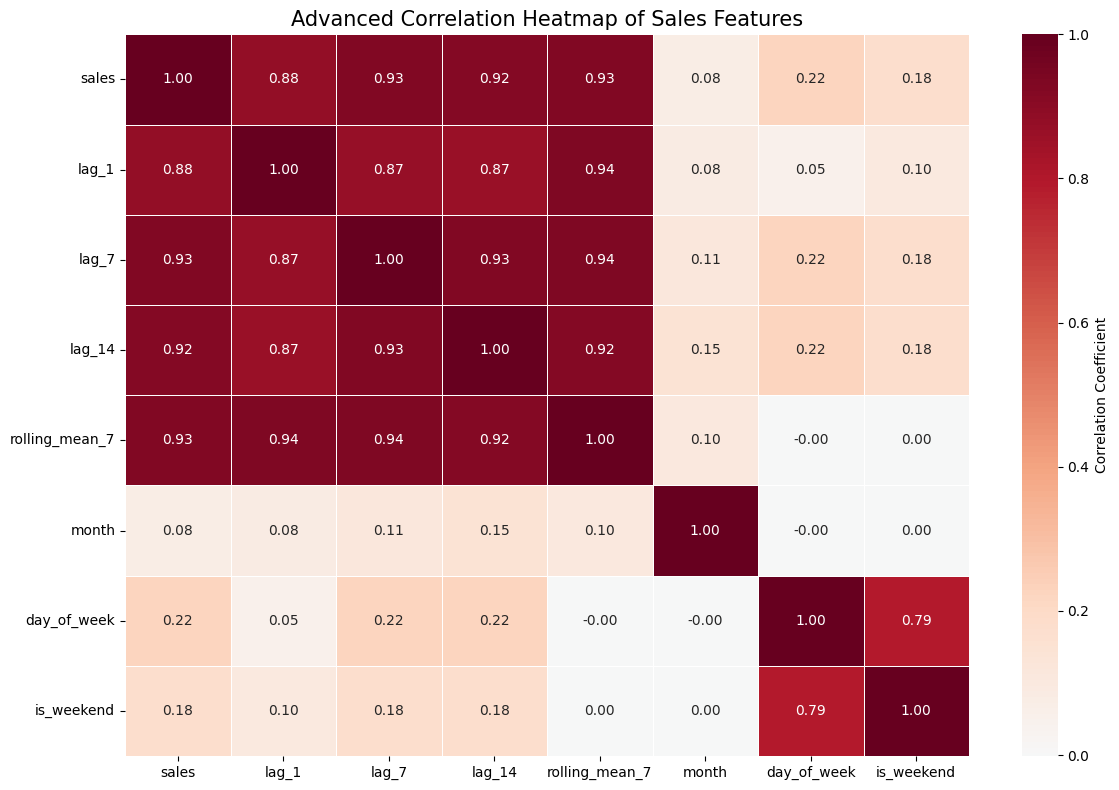

In [19]:
features = [
    'sales',
    'lag_1',
    'lag_7',
    'lag_14',
    'rolling_mean_7',
    'month',
    'day_of_week',
    'is_weekend'
]

correlation = model_df[features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='RdBu_r',
    center=0,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title(
    'Advanced Correlation Heatmap of Sales Features',
    fontsize=15
)

plt.tight_layout()
plt.show()

In [20]:

model_df = model_df.sort_values('date')


dates = sorted(model_df['date'].unique())
split_date = dates[int(len(dates) * 0.8)]


train_df = model_df[model_df['date'] < split_date]
test_df = model_df[model_df['date'] >= split_date]


features = [
    'store', 'item', 'year', 'month',
    'day', 'day_of_week', 'is_weekend',
    'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7'
]

X_train = train_df[features]
y_train = train_df['sales']

X_test = test_df[features]
y_test = test_df['sales']

print("Training and Testing Split Completed!")
print("Split Date:", split_date)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training and Testing Split Completed!
Split Date: 2017-01-03 00:00:00
Training Data: (724500, 11)
Testing Data: (181500, 11)


In [21]:

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Training Completed!")


rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Training Completed!")

Linear Regression Training Completed!
Random Forest Training Completed!


In [22]:

lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

print("MODEL PERFORMANCE COMPARISON")
display(results.round(3))

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,6.981,9.131,0.916
1,Random Forest,6.480,8.445,0.928


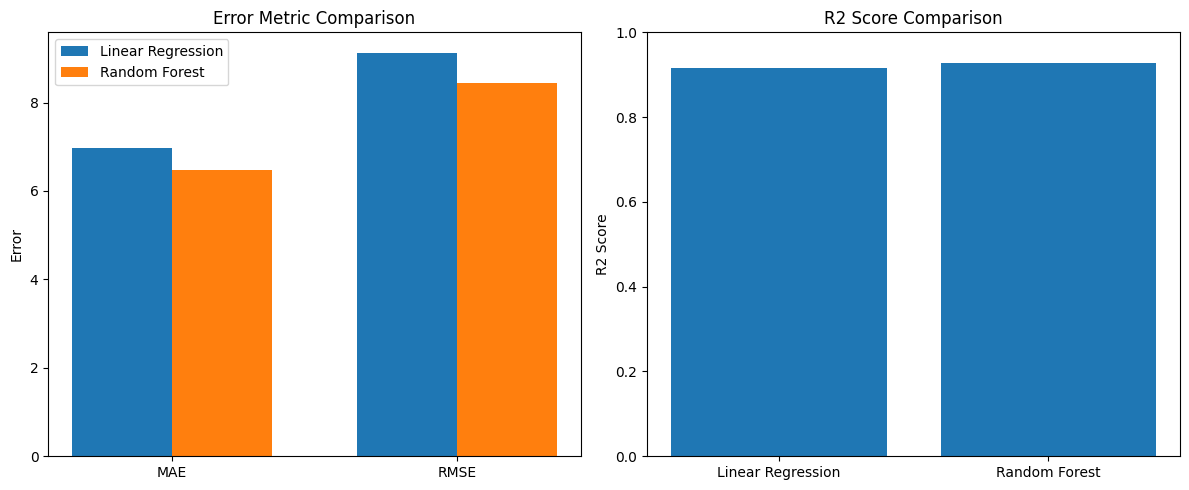

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = ['MAE', 'RMSE']
lr_values = [lr_mae, lr_rmse]
rf_values = [rf_mae, rf_rmse]

x = np.arange(len(metrics))
width = 0.35

axes[0].bar(x - width/2, lr_values, width, label='Linear Regression')
axes[0].bar(x + width/2, rf_values, width, label='Random Forest')

axes[0].set_title('Error Metric Comparison')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylabel('Error')
axes[0].legend()

axes[1].bar(
    ['Linear Regression', 'Random Forest'],
    [lr_r2, rf_r2]
)

axes[1].set_title('R2 Score Comparison')
axes[1].set_ylabel('R2 Score')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

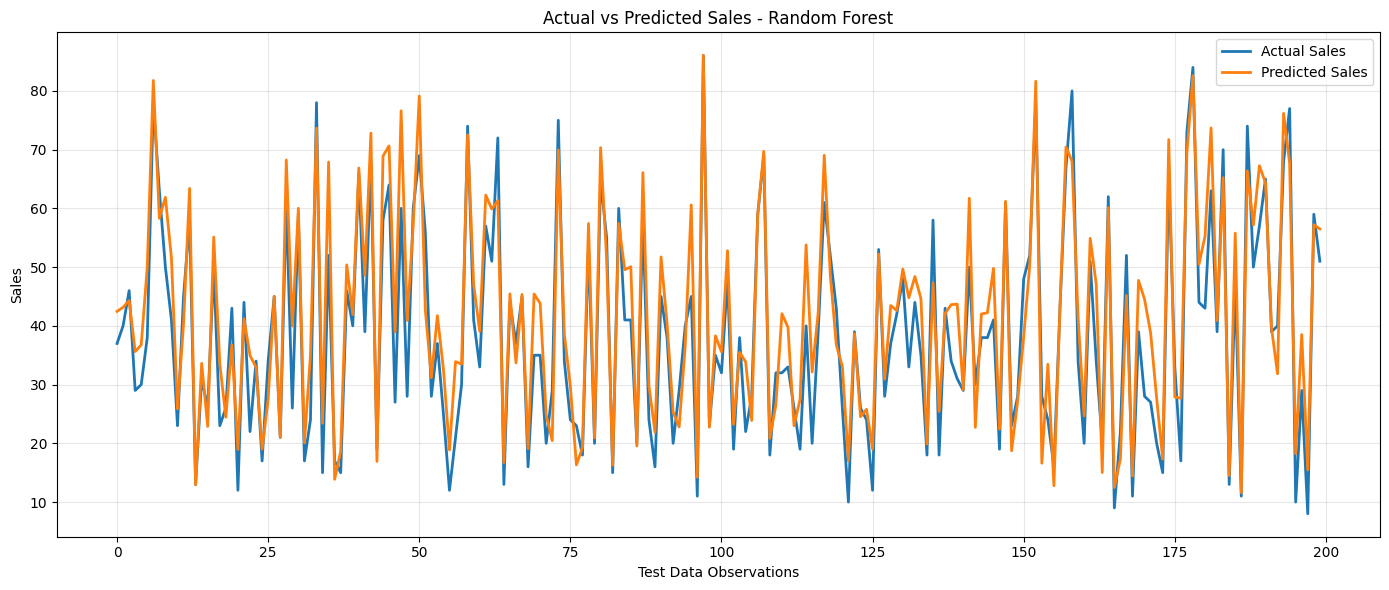

In [24]:

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.values[:200],
    label='Actual Sales',
    linewidth=2
)

plt.plot(
    rf_predictions[:200],
    label='Predicted Sales',
    linewidth=2
)

plt.title('Actual vs Predicted Sales - Random Forest')
plt.xlabel('Test Data Observations')
plt.ylabel('Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

FEATURE IMPORTANCE RANKING


,Feature,Importance
10,rolling_mean_7,0.6648
8,lag_7,0.2592
9,lag_14,0.0265
7,lag_1,0.0191
5,day_of_week,0.0177
3,month,0.0040
4,day,0.0039
1,item,0.0018
0,store,0.0011
6,is_weekend,0.0010


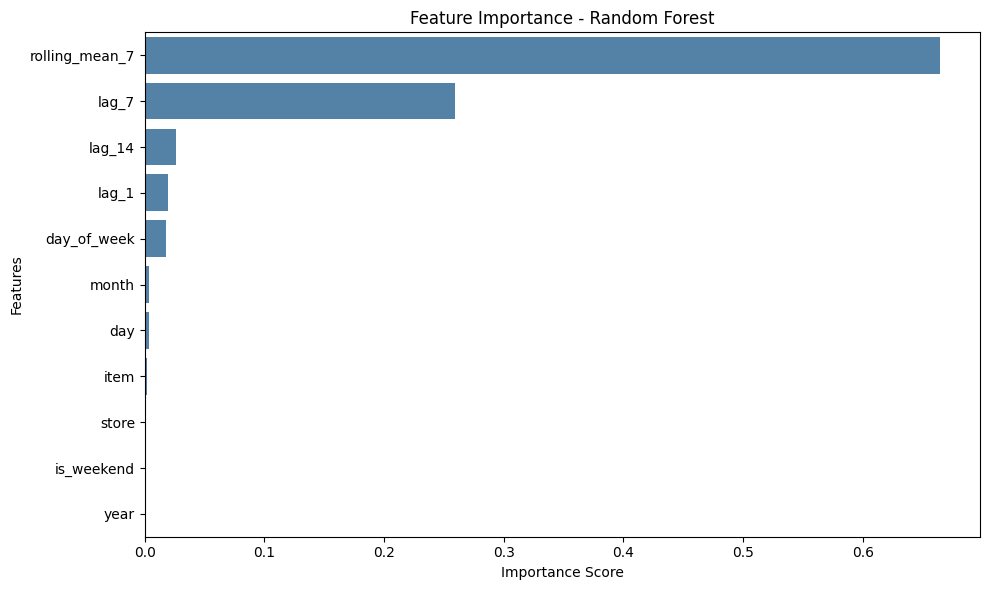

In [25]:


importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print("FEATURE IMPORTANCE RANKING")
display(importance.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [26]:
residuals = y_test.values - rf_predictions

residual_results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': rf_predictions,
    'Error': residuals
})

print("RESIDUAL ANALYSIS")
display(residual_results.head(10).round(2))

print("Mean Error:", round(np.mean(residuals), 3))
print("Mean Absolute Error:", round(np.mean(np.abs(residuals)), 3))
print("Maximum Error:", round(np.max(np.abs(residuals)), 3))

RESIDUAL ANALYSIS


,Actual Sales,Predicted Sales,Error
0,37,42.46,-5.46
1,40,43.16,-3.16
2,46,44.31,1.69
3,29,35.62,-6.62
4,30,36.76,-6.76
5,38,50.04,-12.04
6,78,81.77,-3.77
7,63,58.31,4.69
8,50,61.88,-11.88
9,41,51.54,-10.54


Mean Error: 0.157
Mean Absolute Error: 6.48
Maximum Error: 57.017


## Project Summary and Conclusion

The Store Item Demand Forecasting project analyses historical sales data to identify patterns and predict future product demand.

The dataset was explored using statistical analysis and visualisations, including sales distributions, monthly and yearly trends, store-wise comparisons, product-wise sales, seasonal patterns and correlation analysis.

Feature engineering was performed by creating lag features, a seven-day rolling average and calendar-based features such as month, day of the week and weekend indicators.

Two machine learning models, Linear Regression and Random Forest Regressor, were trained and evaluated using a chronological training and testing split.

The Random Forest model achieved an MAE of **6.480**, RMSE of **8.445** and R² score of **0.928**, performing better than Linear Regression on the evaluated dataset.

Feature importance analysis showed that the seven-day rolling average was the most influential feature, followed by sales from seven days earlier.

Residual analysis further helped examine the difference between actual and predicted sales.

### Conclusion

The project demonstrates how historical sales data and machine learning can be used for demand forecasting. The Random Forest model captured sales patterns effectively and provided promising prediction results. Such forecasts can help retailers improve inventory planning, reduce stock shortages and make better business decisions.

In [27]:
test_path = '/kaggle/input/competitions/demand-forecasting-kernels-only/test.csv'

test_df = pd.read_csv(test_path)
test_df['date'] = pd.to_datetime(test_df['date'])

sample_path = '/kaggle/input/competitions/demand-forecasting-kernels-only/sample_submission.csv'
sample_submission = pd.read_csv(sample_path)

print("Test dataset shape:", test_df.shape)
print("Sample submission shape:", sample_submission.shape)

display(test_df.head())
display(sample_submission.head())

Test dataset shape: (45000, 4)
Sample submission shape: (45000, 2)


,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


,id,sales
0,0,52
1,1,52
2,2,52
3,3,52
4,4,52


In [28]:
final_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_model.fit(model_df[features], model_df['sales'])

print("Final Random Forest Model Trained Successfully!")

Final Random Forest Model Trained Successfully!


In [29]:
history = {}

for (store, item), group in df.groupby(['store', 'item']):
    history[(store, item)] = list(
        group.sort_values('date')['sales']
    )

future_df = test_df.copy()
future_df['original_order'] = np.arange(len(future_df))

future_df = future_df.sort_values(
    ['date', 'store', 'item']
).reset_index(drop=True)

future_predictions = np.zeros(len(future_df))

for date in sorted(future_df['date'].unique()):

    daily = future_df[future_df['date'] == date].copy()

    daily['year'] = daily['date'].dt.year
    daily['month'] = daily['date'].dt.month
    daily['day'] = daily['date'].dt.day
    daily['day_of_week'] = daily['date'].dt.dayofweek
    daily['is_weekend'] = (
        daily['day_of_week'] >= 5
    ).astype(int)

    daily['lag_1'] = daily.apply(
        lambda r: history[(r['store'], r['item'])][-1], axis=1
    )

    daily['lag_7'] = daily.apply(
        lambda r: history[(r['store'], r['item'])][-7], axis=1
    )

    daily['lag_14'] = daily.apply(
        lambda r: history[(r['store'], r['item'])][-14], axis=1
    )

    daily['rolling_mean_7'] = daily.apply(
        lambda r: np.mean(history[(r['store'], r['item'])][-7:]),
        axis=1
    )

    predictions = final_model.predict(daily[features])

    for idx, pred in zip(daily.index, predictions):

        store = daily.loc[idx, 'store']
        item = daily.loc[idx, 'item']

        history[(store, item)].append(pred)

        future_predictions[idx] = pred

future_df['predicted_sales'] = future_predictions

future_df = future_df.sort_values('original_order')

print("Future Predictions Generated Successfully!")
print("Total Predictions:", len(future_predictions))

display(future_df.head(10))

Future Predictions Generated Successfully!
Total Predictions: 45000


,id,date,store,item,original_order,predicted_sales
0,0,2018-01-01,1,1,0,15.602119
500,1,2018-01-02,1,1,1,18.392978
1000,2,2018-01-03,1,1,2,18.862898
1500,3,2018-01-04,1,1,3,19.179608
2000,4,2018-01-05,1,1,4,20.067697
2500,5,2018-01-06,1,1,5,22.841129
3000,6,2018-01-07,1,1,6,22.728857
3500,7,2018-01-08,1,1,7,15.713968
4000,8,2018-01-09,1,1,8,18.018417
4500,9,2018-01-10,1,1,9,16.950914


In [30]:
submission = sample_submission.copy()

submission['sales'] = future_df['predicted_sales'].values

submission.to_csv(
    '/kaggle/working/submission.csv',
    index=False
)

print("Submission file saved successfully!")
print("Total rows:", len(submission))

display(submission.head(10))

Submission file saved successfully!
Total rows: 45000


,id,sales
0,0,15.602119
1,1,18.392978
2,2,18.862898
3,3,19.179608
4,4,20.067697
5,5,22.841129
6,6,22.728857
7,7,15.713968
8,8,18.018417
9,9,16.950914


In [31]:
import joblib

joblib.dump(
    final_model,
    '/kaggle/working/random_forest_model.pkl'
)

model_df.to_csv(
    '/kaggle/working/processed_sales_data.csv',
    index=False
)

print("All project files saved successfully!")

All project files saved successfully!
